In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

import warnings
warnings.filterwarnings("ignore")

In [15]:

DATA_PATH = "../../data/income/raw/adult.csv"

df_raw = pd.read_csv(DATA_PATH)


df_raw.columns = df_raw.columns.str.strip().str.replace("-", "_")
if "class" in df_raw.columns:
    df_raw.rename(columns={"class": "income"}, inplace=True)

print(f"Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head()

Dataset Shape: 48,842 rows, 15 columns
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [16]:

target_col = "income"

df = df_raw.copy()
str_cols = df.select_dtypes(include=["object"]).columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.select_dtypes(include=["object"]).columns if c != target_col]

print(f"Target Variable: '{target_col}'")
print(f"\nNumerical Features ({len(num_cols)}): {num_cols}")
print(f"\nCategorical Features ({len(cat_cols)}): {cat_cols}")

Target Variable: 'income'

Numerical Features (6): ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Features (8): ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [17]:

standard_nans = df.isna().sum()


hidden_qmarks = (df == "?").sum()

missing_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Standard NaN": standard_nans,
    "Hidden '?' Count": hidden_qmarks,
    "Total Missing": standard_nans + hidden_qmarks,
    "Missing %": ((standard_nans + hidden_qmarks) / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Total Missing"] > 0]
print("Features with Missing Values:")
missing_summary.sort_values(by="Total Missing", ascending=False)

Features with Missing Values:


,Data Type,Standard NaN,Hidden '?' Count,Total Missing,Missing %
occupation,str,2809,0,2809,5.75
workclass,str,2799,0,2799,5.73
native_country,str,857,0,857,1.75


In [18]:

dup_count = df.duplicated().sum()
print(f"Duplicate rows detected: {dup_count:,} ({dup_count / len(df) * 100:.2f}%)")


print("\nNumerical Features Statistical Summary:")
display(df[num_cols].describe().T)

Duplicate rows detected: 52 (0.11%)

Numerical Features Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


,Count,Percentage (%)
income,,
<=50K,37155,76.07
>50K,11687,23.93


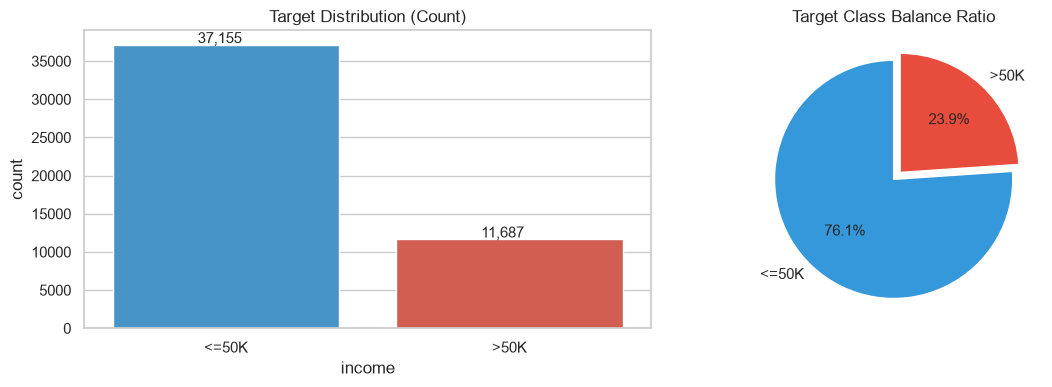

In [20]:

target_counts = df[target_col].value_counts()
target_pct = df[target_col].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_pct.round(2)})
display(dist_df)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))


sns.countplot(data=df, x=target_col, ax=axes[0], palette=["#3498db", "#e74c3c"])
axes[0].set_title("Target Distribution (Count)")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + 0.3, p.get_height() + 200))


axes[1].pie(target_counts, labels=target_counts.index, autopct="%1.1f%%", 
            colors=["#3498db", "#e74c3c"], startangle=90, explode=[0, 0.08])
axes[1].set_title("Target Class Balance Ratio")

plt.tight_layout()
plt.show()

Correlation of Numerical Features with Income >50K:
target_binary     1.000000
education_num     0.332613
age               0.230369
hours_per_week    0.227687
capital_gain      0.223013
capital_loss      0.147554
fnlwgt           -0.006339
Name: target_binary, dtype: float64


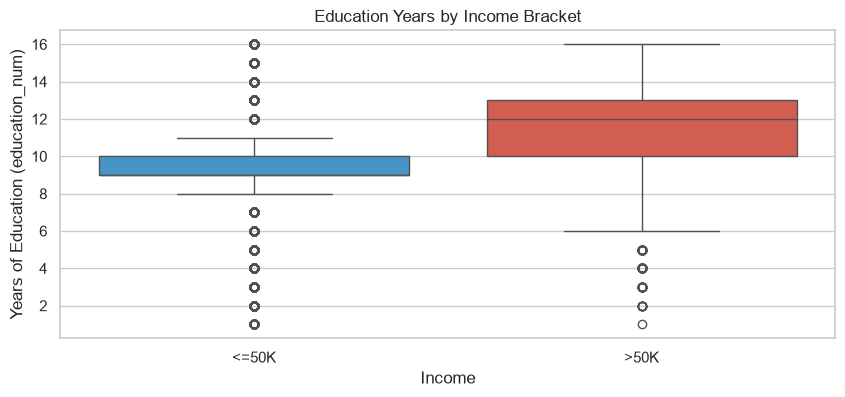

In [21]:

df_temp = df.copy()
df_temp["target_binary"] = (df_temp[target_col].str.contains(">50K")).astype(int)

corr = df_temp[num_cols + ["target_binary"]].corr()["target_binary"].sort_values(ascending=False)
print("Correlation of Numerical Features with Income >50K:")
print(corr)


plt.figure(figsize=(10, 4))
sns.boxplot(data=df_temp, x=target_col, y="education_num", palette=["#3498db", "#e74c3c"])
plt.title("Education Years by Income Bracket")
plt.xlabel("Income")
plt.ylabel("Years of Education (education_num)")
plt.show()

In [22]:
# DATA CLEANING

df_clean = df_raw.copy()

df_clean["income"] = df_clean["income"].astype(str).str.strip().str.rstrip(".")

print("Cleaned Target Value Counts:")
print(df_clean["income"].value_counts())
assert set(df_clean["income"].unique()) == {"<=50K", ">50K"}, "Unexpected values in target!"

Cleaned Target Value Counts:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [23]:

df_clean.replace("?", np.nan, inplace=True)


null_counts = df_clean.isna().sum()
null_percent = (null_counts / len(df_clean) * 100).round(2)
missing_table = pd.DataFrame({"Missing Rows": null_counts, "Percentage (%)": null_percent})
display(missing_table[missing_table["Missing Rows"] > 0])

cols_with_missing = ["workclass", "occupation", "native_country"]
for col in cols_with_missing:
    df_clean[col] = df_clean[col].fillna("Unknown")

print(f"\nRemaining missing values across entire dataset: {df_clean.isna().sum().sum()}")

,Missing Rows,Percentage (%)
workclass,2799,5.73
occupation,2809,5.75
native_country,857,1.75



Remaining missing values across entire dataset: 0


In [24]:
initial_rows = len(df_clean)
duplicates_count = df_clean.duplicated().sum()
print(f"Exact duplicate rows detected: {duplicates_count:,} ({duplicates_count / initial_rows * 100:.2f}%)")


df_clean.drop_duplicates(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print(f"Dataset rows after deduplication: {len(df_clean):,} (dropped {duplicates_count:,} rows)")

Exact duplicate rows detected: 52 (0.11%)
Dataset rows after deduplication: 48,790 (dropped 52 rows)


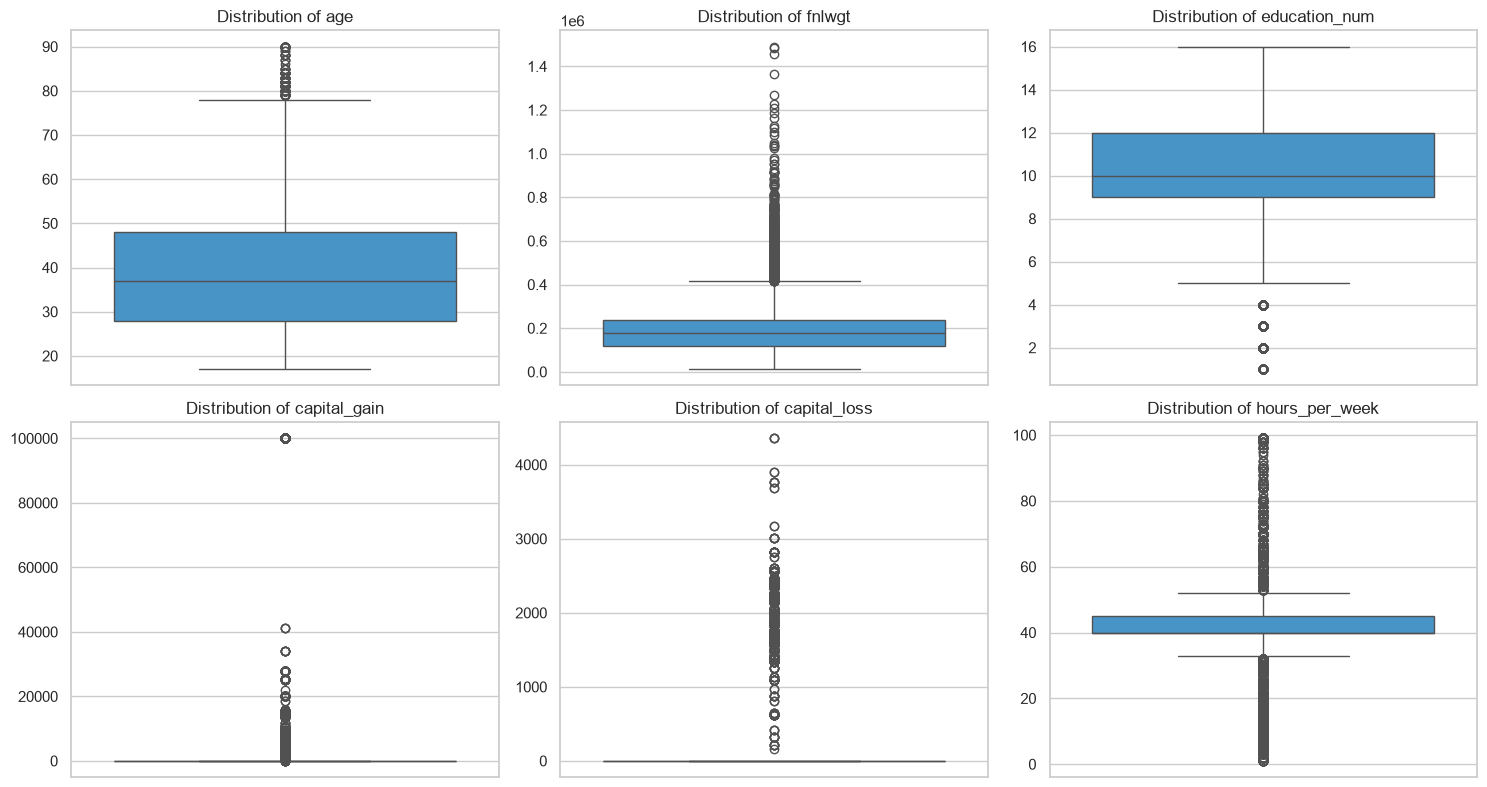

Observations with capped capital_gain = 99,999: 244 (0.50%)
Percentage of people with capital_gain == 0: 91.73%
Percentage of people with capital_loss == 0: 95.32%


In [25]:
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_clean[col], ax=axes[i], color="#3498db")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

cap_gain_99999 = (df_clean["capital_gain"] == 99999).sum()
print(f"Observations with capped capital_gain = 99,999: {cap_gain_99999} ({cap_gain_99999 / len(df_clean) * 100:.2f}%)")
print(f"Percentage of people with capital_gain == 0: {(df_clean['capital_gain'] == 0).mean() * 100:.2f}%")
print(f"Percentage of people with capital_loss == 0: {(df_clean['capital_loss'] == 0).mean() * 100:.2f}%")

In [26]:
columns_to_drop = ["fnlwgt", "education"]

df_clean.drop(columns=columns_to_drop, inplace=True)
print(f"Dropped columns: {columns_to_drop}")
print(f"Remaining columns ({len(df_clean.columns)}): {list(df_clean.columns)}")

Dropped columns: ['fnlwgt', 'education']
Remaining columns (13): ['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


In [28]:

print(f"Cleaned Dataset Dimensions: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print("\nData Types:")
print(df_clean.dtypes)


INTERIM_PATH = "../../data/income/interim/adult_cleaned.csv"
df_clean.to_csv(INTERIM_PATH, index=False)
print(f"\nSaved cleaned interim dataset to '{INTERIM_PATH}' successfully.")
df_clean.head()

Cleaned Dataset Dimensions: 48,790 rows, 13 columns

Data Types:
age               int64
workclass           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
income              str
dtype: object

Saved cleaned interim dataset to '../../data/income/interim/adult_cleaned.csv' successfully.


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Unknown,10,Never-married,Unknown,Own-child,White,Female,0,0,30,United-States,<=50K
